### 표본 분포 (Sampling Distribution)

만약 모집단의 데이터가 10,000건인 상태에서 표본을 1,000번 추출한다면 해당 표본들의 평균도 똑같이 1,000개가 만들어질 것이다.

이 1,000개 평균값들의 분포가 `표본평균의 표본분포`(Sampling Distribution of the Sample Mean)이다.

### 중심극한정리(CLT)

모집단의 분포가 정규분포가 아니더라도, 적절한 조건에서 표본의 크기가 충분히 커지면 표본평균의 분포가 정규분포에 가까워 진다는 의미이다.

여기서 중요한 두가지는
- 원본 데이터의 분포가 정규분포로 변하는건 X
- 표본평균들의 분포가 정규분포에 가까워지는 것

아래 정규분포를 전혀 띄고있지 않은 특정 모집단이 있다. 이 모집단에서 표본을 추출하여 표본 평균들을 계산하여 표본 평균의 크기 별로 어떤 분포를 보이는지 확인해보려고 한다.

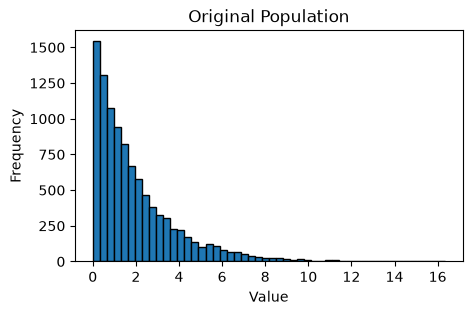

In [4]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))

np.random.seed(42)
population = np.random.exponential(scale=2, size=10000)

plt.hist(population, bins=50, edgecolor="black")

plt.title("Original Population")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.show()

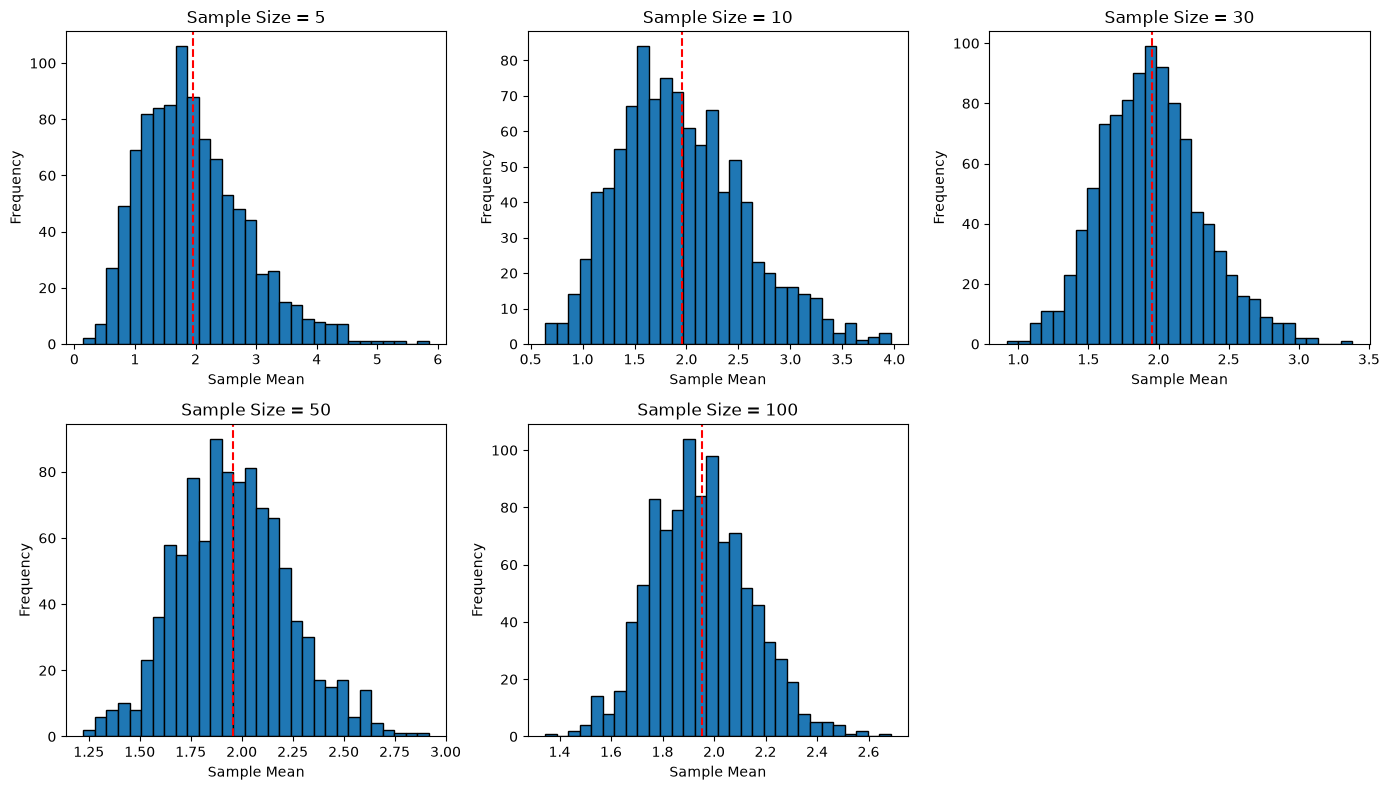

In [ ]:
sample_sizes = [5, 10, 30, 50, 100]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, n in enumerate(sample_sizes):
    sample_means = []

    # 아래 과정을 1000번 반복
    for _ in range(1000):

        # 모집단에서 사이즈 n개만큼 표본 추출
        sample = np.random.choice(
            population,
            size=n,
            replace=False   # 한 표본 안에서 동일한 모집단 원소를 중복 선택하지 않음
        )

        # 해당 표본의 평균을 계산에서 저장
        sample_means.append(sample.mean())

    ax = axes.flat[i]

    ax.hist(sample_means, bins=30, edgecolor="black")
    ax.axvline(population.mean(), color="red", linestyle="--")
    ax.set_title(f"Sample Size = {n}")
    ax.set_xlabel("Sample Mean")
    ax.set_ylabel("Frequency")

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

위의 그래프로 알 수 있는 사실은 표본의 크기가 점점 커질수록 표본평균의 분포가 점점 좁아지면서 가운데에 몰린다는 것이다.